In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             roc_curve, roc_auc_score)

import pickle
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
%matplotlib inline

<H3>2. Load Data </H3>


In [8]:
df = pd.read_csv('titanic2 (1).csv')
print('Shape data:' , df.shape)
df.head()

Shape data: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [10]:
df.describe(include='all')

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
count,891.000000,891.000000,891.000000,891,891,714.000000,891.000000,891.000000,891,891.000000,204,889
unique,NaN,NaN,NaN,891,2,NaN,NaN,NaN,681,NaN,147,3
top,NaN,NaN,NaN,"Dooley, Mr. Patrick",male,NaN,NaN,NaN,347082,NaN,G6,S
freq,NaN,NaN,NaN,1,577,NaN,NaN,NaN,7,NaN,4,644
mean,446.000000,0.383838,2.308642,NaN,NaN,29.699118,0.523008,0.381594,NaN,32.204208,NaN,NaN
std,257.353842,0.486592,0.836071,NaN,NaN,14.526497,1.102743,0.806057,NaN,49.693429,NaN,NaN
min,1.000000,0.000000,1.000000,NaN,NaN,0.420000,0.000000,0.000000,NaN,0.000000,NaN,NaN
25%,223.500000,0.000000,2.000000,NaN,NaN,20.125000,0.000000,0.000000,NaN,7.910400,NaN,NaN
50%,446.000000,0.000000,3.000000,NaN,NaN,28.000000,0.000000,0.000000,NaN,14.454200,NaN,NaN
75%,668.500000,1.000000,3.000000,NaN,NaN,38.000000,1.000000,0.000000,NaN,31.000000,NaN,NaN


<H3>3. EXPLORATORY DATA ANALYSIS (EDA)</H3>

In [11]:
# cek missing value
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
pd.DataFrame({'Jumlah Missing': missing, 'Persentase (%)' : missing_pct.round(2)})

,Jumlah Missing,Persentase (%)
PassengerId,0,0.00
Survived,0,0.00
Pclass,0,0.00
Name,0,0.00
Sex,0,0.00
Age,177,19.87
SibSp,0,0.00
Parch,0,0.00
Ticket,0,0.00
Fare,0,0.00


Survived
0    549
1    342
Name: count, dtype: int64


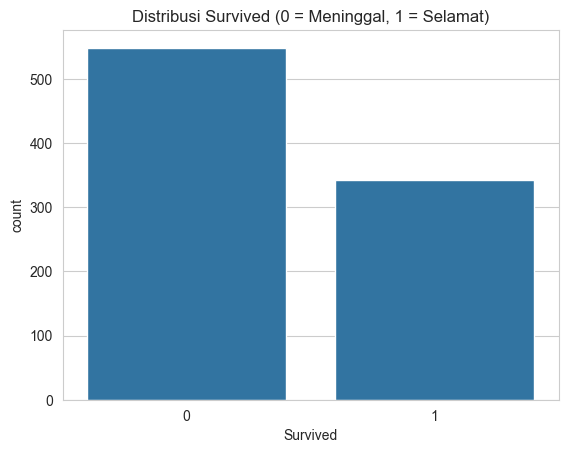

In [12]:
# Distribusi target (Survived)
print(df['Survived'].value_counts())
sns.countplot(data=df, x='Survived')
plt.title('Distribusi Survived (0 = Meninggal, 1 = Selamat)')
plt.show()

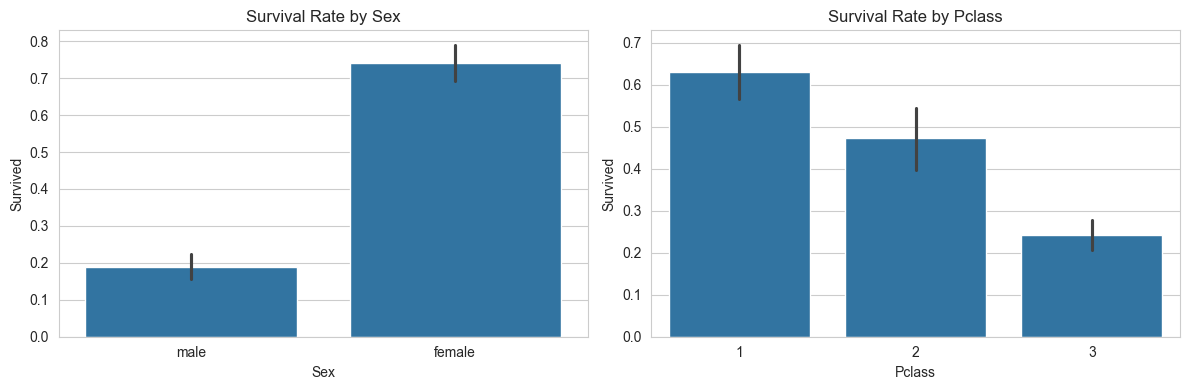

In [13]:
# survival berdasarkan sex dan pclass
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=df, x='Sex', y='Survived', ax=axes[0])
axes[0].set_title('Survival Rate by Sex')

sns.barplot(data=df, x='Pclass', y='Survived', ax=axes[1])
axes[1].set_title('Survival Rate by Pclass')
plt.tight_layout()
plt.show()


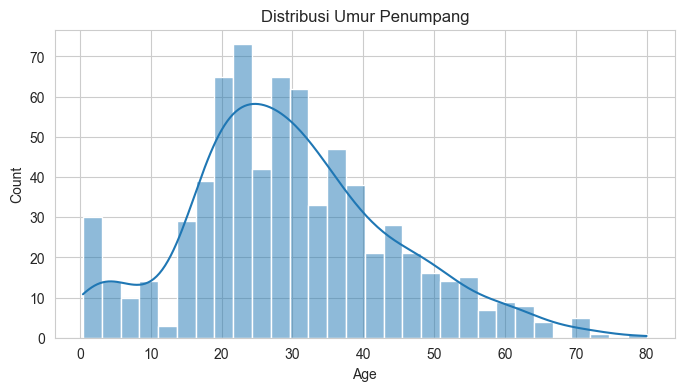

In [14]:
# distribusi umur
plt.figure(figsize=(8,4))
sns.histplot(df['Age']. dropna(), bins=30, kde=True)
plt.title('Distribusi Umur Penumpang')
plt.show()

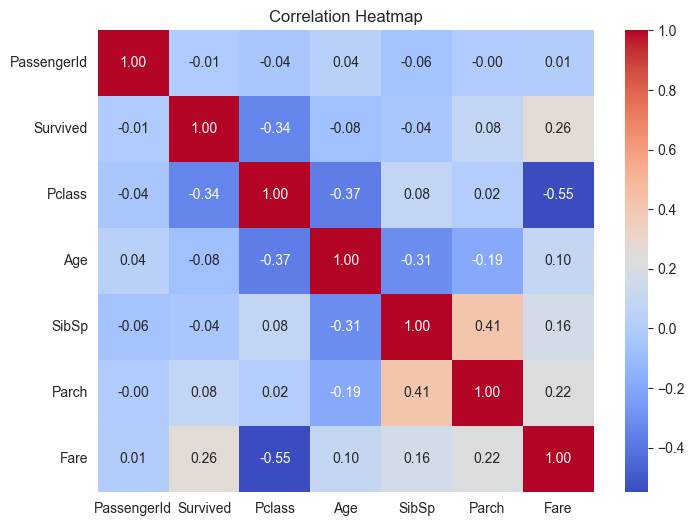

In [15]:
# correlation heatmap (fitur m=numerik)
plt.figure(figsize=(8,6))
sns.heatmap(df.select_dtypes(include=np.number).corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

<H3>TAHAP 4 DATA PREPROCESSING</H3>

In [17]:
import pandas as pd

# 1. Muat dataset terlebih dahulu ke variabel 'data'
data = pd.read_csv('titanic2 (1).csv.') 

# 2. Hapus kolom yang tidak dipakai
data.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'], inplace=True)

# Cek hasilnya
data.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


In [18]:
# isi missing value
data['Age'] = data['Age'].fillna(data['Age'].median())
data['Embarked'] = data['Embarked'].fillna(data['Embarked'].mode()[0])

In [19]:
# cek missing value setelah cleaning
data.isnull().sum()

Survived    0
Pclass      0
Sex         0
Age         0
SibSp       0
Parch       0
Fare        0
Embarked    0
dtype: int64

<h3>Tahap 5 Feature Engineering, Encoding, dan Train-Test Split</h3>

In [20]:
# feature engineering
data['FamilySize'] = data['SibSp'] + data['Parch'] + 1

In [21]:
# Encoding fitur kategorikal
le_sex = LabelEncoder()
le_embarked = LabelEncoder()

data['Sex'] = le_sex.fit_transform(data['Sex'])
# male=1, female=0 (tergantung urutan alfabet)
data['Embarked'] = le_embarked.fit_transform(data['Embarked'])

data.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,FamilySize
0,0,3,1,22.0,1,0,7.2500,2,2
1,1,1,0,38.0,1,0,71.2833,0,2
2,1,3,0,26.0,0,0,7.9250,2,1
3,1,1,0,35.0,1,0,53.1000,2,2
4,0,3,1,35.0,0,0,8.0500,2,1


In [22]:
x = data.drop(columns=['Survived'])
y = data['Survived']

In [23]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

print('Jumlah data latih :', x_train.shape[0])
print('Jumlah data uji   :', x_test.shape[0])

Jumlah data latih : 712
Jumlah data uji   : 179


In [24]:
# standarisasi fitur numerik (penting untuk logistic regression & SVM)
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

<h3>Tahap 6 Modeling</h3>

In [25]:
models = {
    'LogisticRegression': LogisticRegression(max_iter=1000, random_state=42),
    'DecisionTree': DecisionTreeClassifier(random_state=42),
    'RandomForest': RandomForestClassifier(n_estimators=200, random_state=42),
    'SVM': SVC(probability=True, random_state=42)
}

results = {}

In [26]:
result = {}

for name, model in models.items():
    model.fit(x_train_scaled, y_train)
    y_pred = model.predict(x_test_scaled)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    result[name] = {
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1_score': f1
    }

    results_df = pd.DataFrame(result).T.sort_values('Accuracy', ascending=False)
    results_df

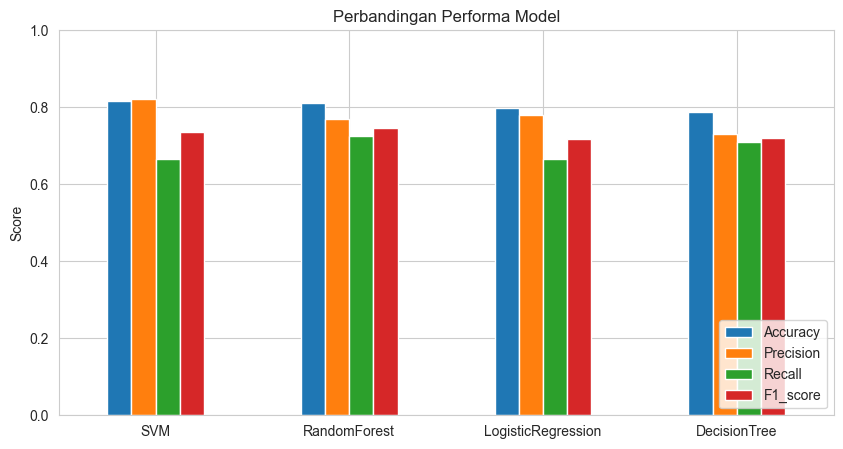

In [27]:
results_df.plot(kind='bar', figsize=(10,5))
plt.title('Perbandingan Performa Model')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.ylim(0,1)
plt.legend(loc='lower right')
plt.show()

<h3>Tahap 7 Evaluasi mendalam random forest</h3>

In [28]:
# 1. Definisikan dictionary yang berisi model
models = {
    'Logistic Regression': LogisticRegression(),
    'Random Forest': RandomForestClassifier(), 
    'Decision Tree': DecisionTreeClassifier()
}

# 2. Latih model (pastikan data latih x_train_scaled dan y_train sudah ada)
models['Random Forest'].fit(x_train_scaled, y_train)

# 3. Setelah dilatih, model baru bisa dipanggil dan digunakan untuk prediksi
best_model = models['Random Forest']
y_pred_best = best_model.predict(x_test_scaled)
y_proba_best = best_model.predict_proba(x_test_scaled)[:, 1]

In [29]:
print('=== Classification Report ===')
print(classification_report(y_test, y_pred_best, target_names=['Meninggal', 'Selamat']))

=== Classification Report ===
              precision    recall  f1-score   support

   Meninggal       0.82      0.88      0.85       110
     Selamat       0.79      0.70      0.74        69

    accuracy                           0.81       179
   macro avg       0.80      0.79      0.79       179
weighted avg       0.81      0.81      0.81       179



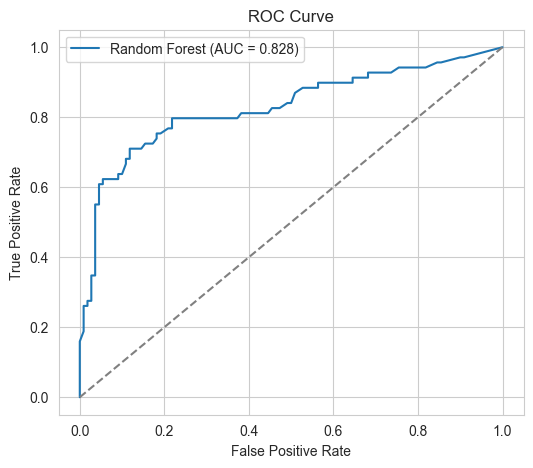

In [30]:
# ROC Curve & AUC
fpr, tpr, _ = roc_curve(y_test, y_proba_best)
auc_score = roc_auc_score(y_test, y_proba_best)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f'Random Forest (AUC = {auc_score:.3f})')
plt.plot([0,1],[0,1],'--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

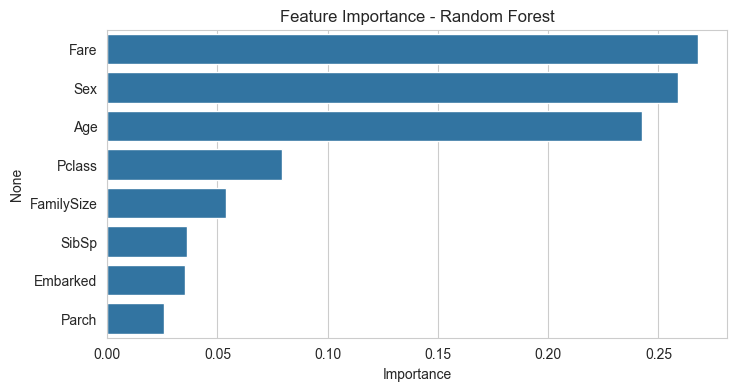

Fare          0.267750
Sex           0.258920
Age           0.242682
Pclass        0.079281
FamilySize    0.053975
SibSp         0.036355
Embarked      0.035255
Parch         0.025783
dtype: float64

In [31]:
# Feature Importance
importances = pd.Series(best_model.feature_importances_, index=x.columns).sort_values(ascending=False)
plt.figure(figsize=(8,4))
sns.barplot(x=importances.values, y=importances.index)
plt.title('Feature Importance - Random Forest')
plt.xlabel('Importance')
plt.show()
importances

In [32]:
# Cross Validation untuk memastikan model stabil (bukan overfitting)
cv_scores = cross_val_score(best_model, x_train_scaled, y_train, cv=5, scoring='accuracy')
print('CV Accuracy tiap fold :', np.round(cv_scores, 3))
print('Rata-rata CV Accuracy :', cv_scores.mean().round(3))
print('Std CV Accuracy       :', cv_scores.std().round(3))

CV Accuracy tiap fold : [0.769 0.713 0.817 0.838 0.796]
Rata-rata CV Accuracy : 0.787
Std CV Accuracy       : 0.043


<h3>Tahap 8 menyimpan model, scaler dan enconder

In [33]:
with open('model.pkl', 'wb') as f:
    pickle.dump(best_model, f)

with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

with open('le_sex.pkl', 'wb') as f:
    pickle.dump(le_sex, f)

with open('le_embarked.pkl', 'wb') as f:
    pickle.dump(le_embarked, f)

print('Model, scaler, dan encoder berhasil disimpan!')
print('Kolom fitur yang dipakai model:', list(x.columns))

Model, scaler, dan encoder berhasil disimpan!
Kolom fitur yang dipakai model: ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked', 'FamilySize']


<h3> Tahap 9 Kesimpulan </h3>

1. Karakteristik dan Eksplorasi Data (EDA): Dataset terdiri dari 891 baris dan 12 kolom dengan tingkat keselamatan keseluruhan sekitar 38%. Terdapat data kosong yang signifikan pada fitur Age (19,87%) dan Cabin (77,10%). Pola menunjukkan bahwa penumpang perempuan dan kelas atas memiliki peluang selamat jauh lebih tinggi, dengan mayoritas penumpang berada di rentang usia 20-40 tahun.

2. Pra-pemrosesan dan Rekayasa Fitur: Tahap persiapan data meliputi penanganan nilai kosong, encoding untuk variabel kategorikal, dan ekstraksi fitur agar algoritma lebih mudah mengenali pola yang ada.

3. Pelatihan dan Pemilihan Model: Pengujian dilakukan terhadap empat algoritma (Logistic Regression, Decision Tree, Random Forest, dan SVM). Random Forest terbukti sebagai algoritma dengan performa paling unggul yang mampu menyeimbangkan akurasi dan pengenalan pola yang kompleks.

4. Analisis Fitur Penting (Feature Importance): Evaluasi pada model Random Forest menunjukkan bahwa jenis kelamin (Sex), kelas tiket (Pclass), dan usia (Age) merupakan faktor yang paling kuat dalam menentukan prediksi keselamatan penumpang.

5. Evaluasi dan Persiapan Deployment: Model telah melalui proses cross-validation untuk memastikan skor tetap stabil dan terhindar dari overfitting. Terakhir, model Random Forest terbaik telah disimpan dalam format pickle dan siap digunakan untuk lingkungan produksi (deployment).